# 02 — Retreino após o alerta da semana 5

Primeiro retreino do laço: disparado pelo primeiro alerta forte de drift de dados, com rótulos só até a semana 4 (atraso de uma semana). Pergunta: **o retreino ajudou?** Notebook de análise: ele só lê o que o `retraining_pipeline` registrou no MLflow; não treina nem promove modelos.

In [1]:
import json, urllib.request
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from credit_drift.data import TARGET
from credit_drift.retraining import analysis
from credit_drift.retraining.candidates import features_of
from credit_drift.retraining.window import build_window
from credit_drift.serving.registry import load_champion
from credit_drift.split import REFERENCE_DIR

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
runs = {r["run_week"]: r for r in analysis.retraining_runs()}
run = runs[5]
print({k: run[k] for k in ('run_week', 'through_week', 'trigger', 'chosen', 'versions')})
gates = run['gates']

C:\pos tech\tech-challenge-04\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'run_week': 5, 'through_week': 4, 'trigger': 'data_drift_major', 'chosen': 'B', 'versions': {'A': '8', 'B': '9'}}


## 1. Por que retreinar: o que o laço viu

O gatilho vem das métricas que o laço de monitoramento enviou ao Prometheus (PSI máximo por semana) e dos alertas desse run.

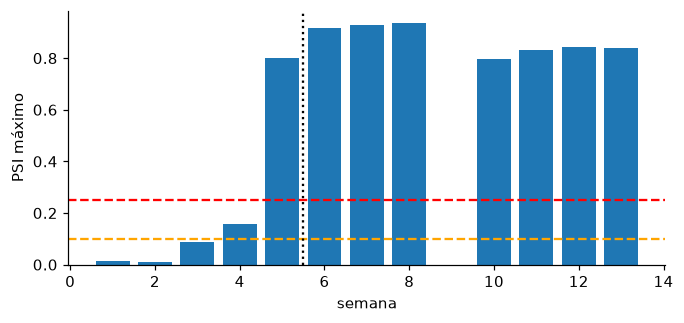

gatilho: data_drift_major no run da semana 5; rótulos disponíveis até a semana 4 (atraso de uma semana)


In [2]:
data = json.load(urllib.request.urlopen("http://127.0.0.1:9090/api/v1/query?query=drift_max_psi"))["data"]["result"]
psi = pd.Series({int(r["metric"]["week"]): float(r["value"][1]) for r in data}).sort_index()
fig, ax = plt.subplots(figsize=(7, 3)); ax.bar(psi.index, psi.values, color="tab:blue")
ax.axhline(0.10, color="orange", ls="--"); ax.axhline(0.25, color="red", ls="--")
ax.axvline(run["run_week"] + 0.5, color="k", ls=":"); ax.set_xlabel("semana"); ax.set_ylabel("PSI máximo")
plt.show()
print(f"gatilho: {run['trigger']} no run da semana {run['run_week']}; rótulos disponíveis até a semana {run['through_week']} (atraso de uma semana)")

## 2. Os dois candidatos e o portão

**A** é o campeão atual recalibrado com rótulos recentes; **B** é a mesma receita do campeão reajustada na janela (Referência + semanas rotuladas, com peso maior para as recentes) e recalibrada. O melhor, escolhido **sem** olhar a fatia do portão, vira `challenger`; o portão é um bootstrap pareado numa fatia separada, sem linhas usadas em ajuste ou calibração.

In [3]:
rows = []
for key in ("A", "B"):
    g = gates[key]
    rows.append({"candidato": key, "versão": run["versions"][key], "escolhido": key == run["chosen"],
                 "custo campeão": round(g["cost_champion"], 4), "custo candidato": round(g["cost_challenger"], 4),
                 "ganho de custo (IC 95%)": f"{g['cost_gain']:+.4f} [{g['cost_gain_ci'][0]:+.4f}, {g['cost_gain_ci'][1]:+.4f}]",
                 "AUC-PR dif. (IC 95%)": f"{g['auc_pr_diff']:+.3f} [{g['auc_pr_diff_ci'][0]:+.3f}, {g['auc_pr_diff_ci'][1]:+.3f}]",
                 "passou": g["passed"]})
print("fatia do portão:", gates["A"]["rows"], "linhas,", gates["A"]["defaulters"], "inadimplentes")
pd.DataFrame(rows).set_index("candidato")

fatia do portão: 4000 linhas, 318 inadimplentes


,versão,escolhido,custo campeão,custo candidato,ganho de custo (IC 95%),AUC-PR dif. (IC 95%),passou
candidato,,,,,,,
A,8,False,0.3147,0.3207,"-0.0061 [-0.0145, +0.0015]","+0.000 [+0.000, +0.000]",False
B,9,True,0.3147,0.3363,"-0.0214 [-0.0375, -0.0058]","-0.014 [-0.030, +0.002]",False


O portão exige que o IC de 95% do ganho de custo fique inteiro acima de zero, que o AUC-PR não seja significativamente pior e que o Brier vença o preditor constante.

## 3. Diagrama de confiabilidade na fatia do portão

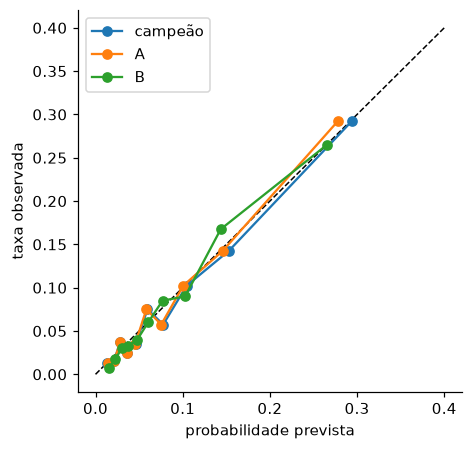

In [4]:
champion = load_champion()
window = build_window(run["through_week"], pd.read_parquet(REFERENCE_DIR / "train.parquet"))
gate = window.gate.reset_index(drop=True)
versions = {"campeão": champion.version, "A": run["versions"]["A"], "B": run["versions"]["B"]}
models = {n: mlflow.sklearn.load_model(f"models:/credit_scoring/{v}") for n, v in versions.items()}
X = features_of(gate)
frame = pd.DataFrame({TARGET: gate[TARGET].to_numpy(), **{n: m.predict_proba(X)[:, 1] for n, m in models.items()}})
fig, ax = plt.subplots(figsize=(4.5, 4.5)); ax.plot([0, 0.4], [0, 0.4], "k--", lw=1)
for name in versions:
    table = analysis.reliability(frame, name); ax.plot(table["predicted"], table["observed"], "o-", label=name)
ax.set_xlabel("probabilidade prevista"); ax.set_ylabel("taxa observada"); ax.legend(); plt.show()

## 4. Os candidatos nas semanas seguintes (semanas 6–13, sem a 9)

Os modelos pontuam **as mesmas semanas** que nenhum deles viu no ajuste, então a diferença isola o efeito da intervenção. Como o portão rejeitou o candidato, o campeão seguiu servindo; os candidatos rodam só offline (sombra).

In [5]:
names = {"v1 (campeão)": champion.version, "A": run["versions"]["A"], "B": run["versions"]["B"]}
scored = analysis.score_weeks(names, [6, 7, 8, 10, 11, 12, 13])
weekly = analysis.per_week(scored, list(names))
weekly.pivot(index="week", columns="model", values="auc_pr").round(3)

model,A,B,v1 (campeão)
week,,,
6,0.252,0.245,0.252
7,0.263,0.251,0.263
8,0.182,0.180,0.182
10,0.196,0.183,0.196
11,0.176,0.171,0.176
12,0.212,0.204,0.212
13,0.206,0.206,0.206


In [6]:
base = "v1 (campeão)"
rows = []
for name in names:
    if name == base:
        continue
    g = analysis.gap(scored, base, name)
    rows.append({"modelo": name, **{k: round(v, 4) for k, v in g.items()
                                   if k in ("auc_pr", "auc_pr_low", "auc_pr_high", "cost", "cost_low", "cost_high", "brier")}})
pd.DataFrame(rows).set_index("modelo")

,auc_pr,auc_pr_low,auc_pr_high,brier,cost,cost_low,cost_high
modelo,,,,,,,
A,0.0000,0.0000,0.0000,-0.0001,-0.0012,-0.0035,0.0013
B,-0.0062,-0.0108,-0.0017,0.0003,0.0069,0.0014,0.0125


As lacunas são `modelo − v1` nas semanas pooladas, com intervalo de bootstrap pareado. Para custo e Brier, valores negativos são melhores.

## 5. Por fatia: dentro e fora do segmento com drift de conceito

O segmento injetado (idade ≤ 45 e renda ≤ mediana do treino) é verdade do simulador, usado só aqui, offline.

In [7]:
rows = []
for label, mask in (("dentro do segmento", scored["in_segment"]), ("fora do segmento", ~scored["in_segment"])):
    part = scored[mask]
    for name in names:
        rows.append({"grupo": label, "modelo": name, "linhas": len(part), "AUC-PR": round(analysis.metrics(part, name)["auc_pr"], 3)})
pd.DataFrame(rows).pivot(index="grupo", columns="modelo", values="AUC-PR")

modelo,A,B,v1 (campeão)
grupo,,,
dentro do segmento,0.203,0.193,0.203
fora do segmento,0.213,0.209,0.213


**Leitura.** O drift das semanas 3–5 é de covariáveis: o ranking do modelo quase não muda. Recalibrar (A) é neutro: mesmo AUC-PR do v1 em todas as semanas e custo praticamente igual (diferença −0,0012, IC que inclui zero). Reajustar o modelo (B) com só 4 semanas rotuladas, 3 mil linhas do regime novo, foi **pior**: AUC-PR −0,006 (IC 95% −0,011 a −0,002) e custo +0,007 (IC 0,001 a 0,013) nas semanas 6–13. O portão acertou ao rejeitar os dois: o campeão (v1) seguiu servindo. Retreinar não é sempre a resposta; recalibrar é a correção barata, e aqui nem ela se pagou. Nenhum dos dois viu o drift de conceito das semanas 8 em diante.